# <span style="color: #a855f7">Linear regression</span>

<span style="color: #a855f7">передбачення, MAE, MSE, RMSE, градієнтний спуск, порівняння learning rates, модель на California Housing</span>

In [1]:
from html import escape
from io import StringIO

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import HTML, display
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.utils import Bunch

PURPLE = "#a855f7"
PINK = "#f472b6"
BLUE = "#60a5fa"


def colorize(value, *, index=True):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        table = value.to_frame() if isinstance(value, pd.Series) else value
        display(HTML(table.to_html(border=0, index=index).replace(
            '<table ', '<table style="color: #a855f7; margin-left: 0; margin-right: auto; border-collapse: collapse" '
        ).replace(
            "<th>", '<th style="padding: 6px 12px; border-bottom: 1px solid #746a80">'
        ).replace(
            "<td>", '<td style="padding: 6px 12px; border-bottom: 1px solid #746a80">'
        )))
    else:
        display(HTML(f'<pre style="color: #a855f7; background: transparent">{escape(str(value))}</pre>'))


plt.style.use("dark_background")
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
    "figure.facecolor": "#111116",
    "axes.facecolor": "#111116",
    "axes.edgecolor": "#746a80",
    "axes.labelcolor": "#e9d5ff",
    "axes.titlecolor": "#e9d5ff",
    "text.color": "#e9d5ff",
    "xtick.color": "#d8c8ed",
    "ytick.color": "#d8c8ed",
    "grid.color": "#746a80",
    "grid.alpha": 0.25,
    "lines.linewidth": 2,
    "font.size": 10,
})

## <span style="color: #a855f7">Manual prediction</span>

<span style="color: #a855f7">формула ŷ = w * x + b, w = 450 USD/m², b = 15000 USD</span>

<div style="color: #a855f7">
<p>65 m²: 450 * 65 + 15000 = 44250 USD</p>
<p>120 m²: 450 * 120 + 15000 = 69000 USD</p>
<p>50 m²: 450 * 50 + 15000 = 37500 USD</p>
<p>51 m²: 450 * 51 + 15000 = 37950 USD</p>
<p>increase: 37950 − 37500 = 450 USD</p>
</div>

In [2]:
areas = np.array([65, 120, 50, 51])
prices = 450 * areas + 15000
colorize(pd.DataFrame({"area (m²)": areas, "prediction (USD)": prices}))
colorize(f"increase from 50 to 51 m²: {prices[3] - prices[2]} USD")

,area (m²),prediction (USD)
0,65,44250
1,120,69000
2,50,37500
3,51,37950


## <span style="color: #a855f7">Manual quality metrics</span>

<span style="color: #a855f7">залишки y - ŷ: -1000, 1000, 2000, MAE і RMSE вимірюються в USD, MSE - в USD²</span>

<div style="color: #a855f7">
<p>MAE = (|-1000| + |1000| + |2000|) / 3 = 4000 / 3 ≈ 1333.33 USD</p>
<p>MSE = ((-1000)² + 1000² + 2000²) / 3 = 6000000 / 3 = 2000000 USD²</p>
<p>RMSE = √2000000 ≈ 1414.21 USD</p>
</div>

In [3]:
y_true = np.array([30000, 45000, 60000], dtype=float)
y_pred = np.array([31000, 44000, 58000], dtype=float)
residuals = y_true - y_pred
mae = np.abs(residuals).mean()
mse = np.square(residuals).mean()
rmse = np.sqrt(mse)
colorize(pd.DataFrame({
    "actual (USD)": y_true,
    "prediction (USD)": y_pred,
    "residual (USD)": residuals,
    "absolute error (USD)": np.abs(residuals),
    "squared error (USD²)": np.square(residuals),
}))
colorize(f"MAE: {mae:.2f} USD\nMSE: {mse:.2f} USD²\nRMSE: {rmse:.2f} USD")

,actual (USD),prediction (USD),residual (USD),absolute error (USD),squared error (USD²)
0,30000.0,31000.0,-1000.0,1000.0,1000000.0
1,45000.0,44000.0,1000.0,1000.0,1000000.0
2,60000.0,58000.0,2000.0,2000.0,4000000.0


## <span style="color: #a855f7">NumPy prediction</span>

<span style="color: #a855f7">скалярна вага для однієї ознаки, вектор ваг для кількох, перевірка форм і скінченності значень</span>

In [4]:
def predict(X, w, b):
    X = np.asarray(X, dtype=float)
    w = np.asarray(w, dtype=float)
    if X.ndim not in (1, 2) or X.size == 0:
        raise ValueError("X must be a nonempty 1D or 2D array")
    if w.ndim > 1 or w.size == 0:
        raise ValueError("w must be a scalar or a nonempty 1D array")
    if np.ndim(b) != 0 or not np.isfinite(b):
        raise ValueError("b must be a finite scalar")
    if not np.isfinite(X).all() or not np.isfinite(w).all():
        raise ValueError("X and w must contain only finite values")
    if w.ndim == 0:
        if X.ndim == 2:
            if X.shape[1] != 1:
                raise ValueError("A scalar weight requires one feature")
            X = X[:, 0]
        return X * w + b
    if X.shape[-1] != w.size:
        raise ValueError("The feature count must match the weight count")
    return X @ w + b


single_features = np.array([50, 70, 90])
multiple_features = np.array([[70, 2], [100, 3]])
colorize(f"single feature: {predict(single_features, 500, 10000)}")
colorize(f"multiple features: {predict(multiple_features, [500, 3000], 10000)}")

## <span style="color: #a855f7">Gradient descent</span>

<span style="color: #a855f7">нульові початкові w і b, 1000 оновлень з lr = 0.0001</span>

<span style="color: #a855f7">в тз MSE записується перед оновленням, тут - після, щоб останній loss відповідав фінальним w і b і прямій на графіку</span>

<span style="color: #a855f7">для стабільних запусків виконуються всі задані epochs, при числовому переповненні нестабільний запуск зупиняється раніше, в історію додається inf як позначення переповнення, повернуті w і b залишаються з останньої успішної ітерації, це захист від подальших обчислень з inf і nan</span>

,method,w,b,MSE (USD²)
0,Gradient descent: 1000 epochs,612.27,142.75,12915093.31
1,Least squares reference,439.56,13767.40,3764267.13


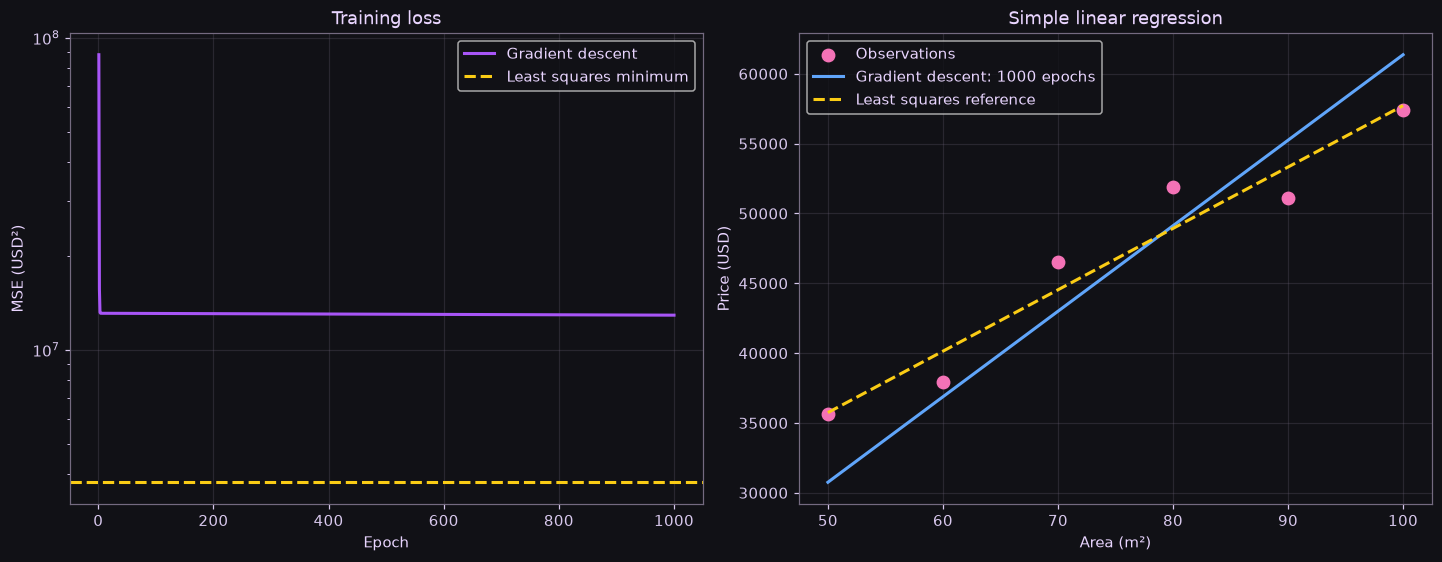

In [5]:
def gradient_descent_simple(X, y, lr=0.01, epochs=1000):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)
    if X.ndim != 1 or X.size == 0 or y.shape != X.shape:
        raise ValueError("X and y must be nonempty 1D arrays of equal length")
    if not np.isfinite(X).all() or not np.isfinite(y).all():
        raise ValueError("X and y must contain only finite values")
    if not np.isscalar(lr) or not np.isfinite(lr) or lr <= 0:
        raise ValueError("lr must be finite and positive")
    if isinstance(epochs, bool) or not isinstance(epochs, (int, np.integer)) or epochs <= 0:
        raise ValueError("epochs must be a positive integer")
    w, b = 0.0, 0.0
    loss_history = []
    for _ in range(epochs):
        try:
            with np.errstate(over="raise", invalid="raise"):
                residuals = y - (w * X + b)
                dw = -2 * np.mean(X * residuals)
                db = -2 * np.mean(residuals)
                next_w = w - lr * dw
                next_b = b - lr * db
                loss = np.mean(np.square(y - (next_w * X + next_b)))
        except FloatingPointError:
            loss_history.append(np.inf)
            break
        w, b = float(next_w), float(next_b)
        loss_history.append(float(loss))
    return w, b, np.asarray(loss_history)


rng = np.random.default_rng(42)
X = np.array([50, 60, 70, 80, 90, 100], dtype=float)
y = 500 * X + 10000 + rng.normal(0, 2000, X.size)
w_final, b_final, losses = gradient_descent_simple(X, y, lr=0.0001, epochs=1000)
colorize(f"w: {w_final:.2f}\nb: {b_final:.2f}\nfinal MSE: {losses[-1]:.2f} USD²")

design_matrix = np.column_stack((X, np.ones_like(X)))
least_squares_w, least_squares_b = np.linalg.lstsq(design_matrix, y, rcond=None)[0]
least_squares_predictions = predict(X, least_squares_w, least_squares_b)
least_squares_mse = np.mean(np.square(y - least_squares_predictions))
colorize(pd.DataFrame({
    "method": ["Gradient descent: 1000 epochs", "Least squares reference"],
    "w": [w_final, least_squares_w],
    "b": [b_final, least_squares_b],
    "MSE (USD²)": [losses[-1], least_squares_mse],
}).round(2))
colorize(f"MSE above minimum: {losses[-1] - least_squares_mse:.2f} USD²")

fig, (loss_ax, model_ax) = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
loss_ax.plot(np.arange(1, losses.size + 1), losses, color=PURPLE, label="Gradient descent")
loss_ax.axhline(least_squares_mse, color="#facc15", linestyle="--", label="Least squares minimum")
loss_ax.legend()
loss_ax.set(title="Training loss", xlabel="Epoch", ylabel="MSE (USD²)", yscale="log")
model_ax.scatter(X, y, color=PINK, s=65, label="Observations")
model_ax.plot(X, predict(X, w_final, b_final), color=BLUE, label="Gradient descent: 1000 epochs")
model_ax.plot(X, least_squares_predictions, color="#facc15", linestyle="--", label="Least squares reference")
model_ax.set(title="Simple linear regression", xlabel="Area (m²)", ylabel="Price (USD)")
model_ax.legend()
for ax in (loss_ax, model_ax):
    ax.grid()
    ax.set_axisbelow(True)
plt.show()

<span style="color: #a855f7">пунктир показує розв'язок методу найменших квадратів через np.linalg.lstsq, який мінімізує MSE для цих самих даних і лінійної моделі, порівняння показує, що після 1000 епох градієнтний спуск ще не дійшов мінімуму</span>

## <span style="color: #a855f7">Learning rate comparison</span>

<span style="color: #a855f7">одна вибірка, однакові початкові параметри, ліміт 1000 епох, логарифмічна шкала MSE показує розбіжність, вставка збільшує початок стабільних кривих</span>

<span style="color: #a855f7">lr - розмір кроку, recorded epochs - к-сть записів loss включно з позначкою переповнення, last finite MSE - останній скінченний loss, completed означає виконання всіх 1000 епох, overflow stopped - зупинку через переповнення, запис e+307 означає множення на 10 у степені 307</span>

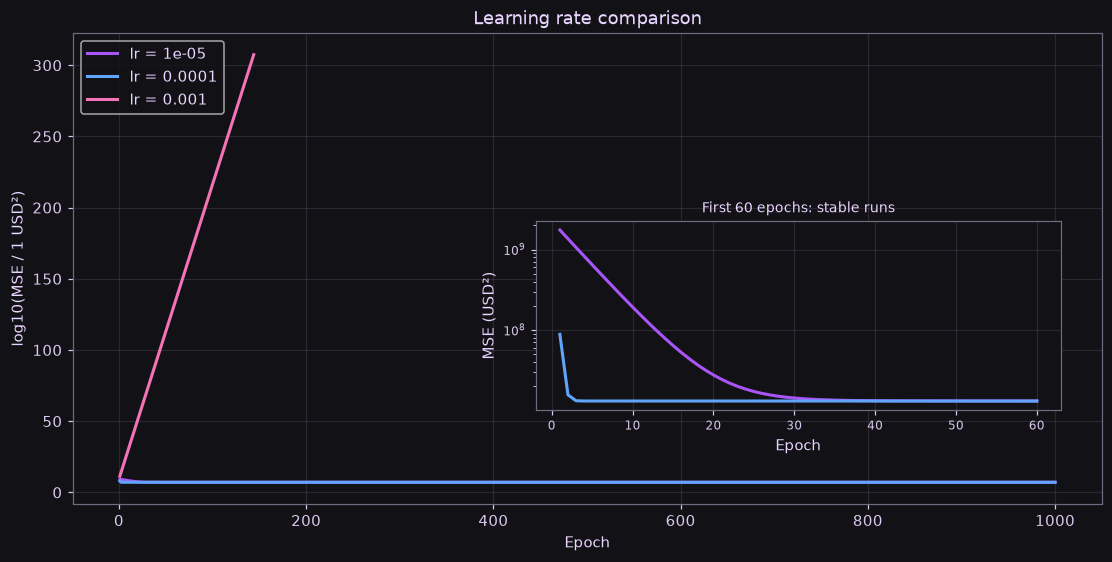

lr,recorded epochs,last finite MSE (USD²),status
0.00001,1000,"13,078,912.13",completed
0.00010,1000,"12,915,093.31",completed
0.00100,145,2.410e+307,overflow stopped


In [6]:
learning_rates = [0.00001, 0.0001, 0.001]
histories = {}
rate_results = []
fig, ax = plt.subplots(layout="constrained")
zoom_ax = ax.inset_axes((0.45, 0.20, 0.51, 0.40))
for lr, color in zip(learning_rates, [PURPLE, BLUE, PINK], strict=True):
    _, _, history = gradient_descent_simple(X, y, lr=lr, epochs=1000)
    histories[lr] = history
    finite = np.isfinite(history)
    epochs_axis = np.arange(1, history.size + 1)
    ax.plot(epochs_axis[finite], np.log10(history[finite]), color=color, label=f"lr = {lr:g}")
    if finite.all():
        zoom_ax.plot(epochs_axis[:60], history[:60], color=color)
    rate_results.append({
        "lr": lr,
        "recorded epochs": history.size,
        "last finite MSE (USD²)": history[finite][-1],
        "status": "finite" if finite.all() else "diverged; overflow stopped",
    })
ax.set(title="Learning rate comparison", xlabel="Epoch", ylabel="log10(MSE / 1 USD²)")
ax.legend(loc="upper left")
ax.grid()
zoom_ax.set(title="First 60 epochs: stable runs", xlabel="Epoch", ylabel="MSE (USD²)", yscale="log")
zoom_ax.tick_params(labelsize=8)
zoom_ax.title.set_fontsize(9)
zoom_ax.grid()
plt.show()
rate_table = pd.DataFrame(rate_results)
rate_table["lr"] = rate_table["lr"].map(lambda value: f"{value:.5f}")
rate_table["last finite MSE (USD²)"] = rate_table["last finite MSE (USD²)"].map(
    lambda value: f"{value:,.2f}" if value < 1e12 else f"{value:.3e}"
)
rate_table["status"] = rate_table["status"].replace({
    "finite": "completed", "diverged; overflow stopped": "overflow stopped",
})
colorize("Learning rate results")
colorize(rate_table, index=False)

<span style="color: #a855f7">lr = 0.0001 швидше зменшує MSE на початку, ніж lr = 0.00001. Значення lr = 0.001 завелике для цієї вибірки і призводить до розбіжності, за 1000 епох на немасштабованих даних модель може не встигнути підібрати оптимальні значення ваги та зміщення</span>

## <span style="color: #a855f7">California Housing exploration</span>

<span style="color: #a855f7">20640 спостережень, перегляд head, info і describe, MedHouseVal вимірюється в одиницях 100000 USD, перше завантаження потребує інтернету, потім scikit-learn використовує локальний кеш</span>

<span style="color: #a855f7">California Housing містить агреговані дані перепису США 1990 року, один рядок - група кварталів у Каліфорнії, 8 ознак описують дохід, житло, населення і координати, MedHouseVal - медіанна вартість житла, fetch_california_housing завантажує готовий архів із Figshare лише за відсутності локального кешу</span>

<span style="color: #a855f7">head - перші 5 рядків, info - структура таблиці, non-null - к-сть заповнених значень, missing - пропуски, float64 - числовий тип із плаваючою крапкою, describe - статистика колонок: count, mean, std, min, квартилі 25/50/75% і max</span>

In [7]:
data = fetch_california_housing(as_frame=True, return_X_y=False)
if not isinstance(data, Bunch):
    raise TypeError("Expected a dataset Bunch")
if not isinstance(data.frame, pd.DataFrame):
    raise TypeError("Expected a pandas DataFrame")
df = data.frame.copy()
colorize("First 5 rows - df.head()")
colorize(df.head())
info_buffer = StringIO()
df.info(buf=info_buffer)
schema = pd.DataFrame({
    "column": df.columns,
    "non-null": df.notna().sum().to_numpy(),
    "missing": df.isna().sum().to_numpy(),
    "dtype": df.dtypes.astype(str).to_numpy(),
})
colorize("DataFrame structure - df.info() summary")
colorize(f"rows: {df.shape[0]} | columns: {df.shape[1]}")
colorize(schema, index=False)
colorize("Summary statistics - df.describe()")
colorize(df.describe().round(3))

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


column,non-null,missing,dtype
MedInc,20640,0,float64
HouseAge,20640,0,float64
AveRooms,20640,0,float64
AveBedrms,20640,0,float64
Population,20640,0,float64
AveOccup,20640,0,float64
Latitude,20640,0,float64
Longitude,20640,0,float64
MedHouseVal,20640,0,float64


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000,20640.000,20640.000,20640.000,20640.000,20640.000,20640.000,20640.000,20640.000
mean,3.871,28.639,5.429,1.097,1425.477,3.071,35.632,-119.570,2.069
std,1.900,12.586,2.474,0.474,1132.462,10.386,2.136,2.004,1.154
min,0.500,1.000,0.846,0.333,3.000,0.692,32.540,-124.350,0.150
25%,2.563,18.000,4.441,1.006,787.000,2.430,33.930,-121.800,1.196
50%,3.535,29.000,5.229,1.049,1166.000,2.818,34.260,-118.490,1.797
75%,4.743,37.000,6.052,1.100,1725.000,3.282,37.710,-118.010,2.647
max,15.000,52.000,141.909,34.067,35682.000,1243.333,41.950,-114.310,5.000


## <span style="color: #a855f7">Correlation matrix</span>

<span style="color: #a855f7">Pearson-кореляції всіх числових колонок, найсильніша ознака для моделі обирається окремо на train за абсолютною кореляцією з ціллю</span>

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
MedInc,1.000,-0.119,0.327,-0.062,0.005,0.019,-0.080,-0.015,0.688
HouseAge,-0.119,1.000,-0.153,-0.078,-0.296,0.013,0.011,-0.108,0.106
AveRooms,0.327,-0.153,1.000,0.848,-0.072,-0.005,0.106,-0.028,0.152
AveBedrms,-0.062,-0.078,0.848,1.000,-0.066,-0.006,0.070,0.013,-0.047
Population,0.005,-0.296,-0.072,-0.066,1.000,0.070,-0.109,0.100,-0.025
AveOccup,0.019,0.013,-0.005,-0.006,0.070,1.000,0.002,0.002,-0.024
Latitude,-0.080,0.011,0.106,0.070,-0.109,0.002,1.000,-0.925,-0.144
Longitude,-0.015,-0.108,-0.028,0.013,0.100,0.002,-0.925,1.000,-0.046
MedHouseVal,0.688,0.106,0.152,-0.047,-0.025,-0.024,-0.144,-0.046,1.000


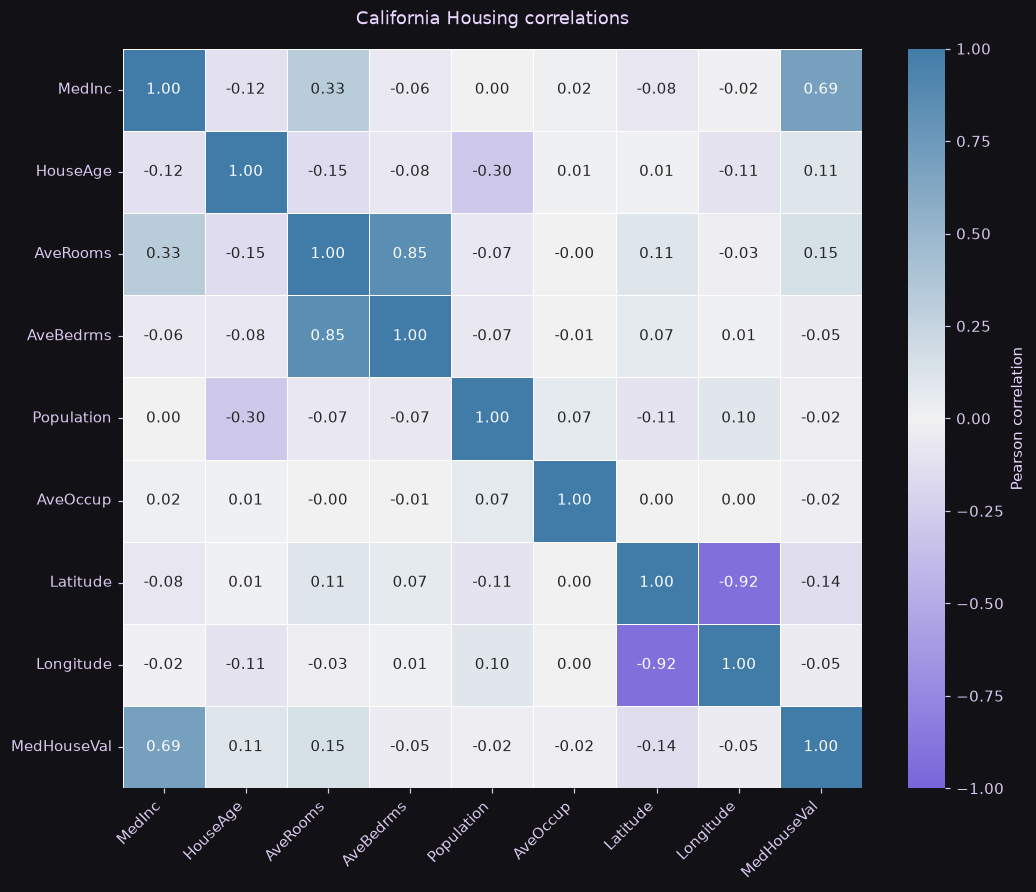

In [8]:
correlation_matrix = df.corr()
colorize(correlation_matrix.round(3))
fig, ax = plt.subplots(figsize=(10, 8), layout="constrained")
sns.heatmap(
    correlation_matrix, annot=True, fmt=".2f", vmin=-1, vmax=1, center=0,
    cmap=sns.diverging_palette(270, 240, as_cmap=True), square=True,
    linewidths=0.5, ax=ax, cbar_kws={"label": "Pearson correlation"},
)
ax.set_title("California Housing correlations", pad=16)
ax.tick_params(axis="x", labelrotation=45)
ax.tick_params(axis="y", labelrotation=0)
plt.setp(ax.get_xticklabels(), ha="right")
plt.show()

## <span style="color: #a855f7">Single-feature housing model</span>

<span style="color: #a855f7">поділ train/test 80/20 з random_state = 42, відбір ознаки, навчання лише на train, MAE і RMSE на test в USD, R² безрозмірний</span>

,MedHouseVal
MedInc,0.6906
AveRooms,0.1585
Latitude,-0.1430
HouseAge,0.1037
AveBedrms,-0.0514
Longitude,-0.0463
Population,-0.0260
AveOccup,-0.0220


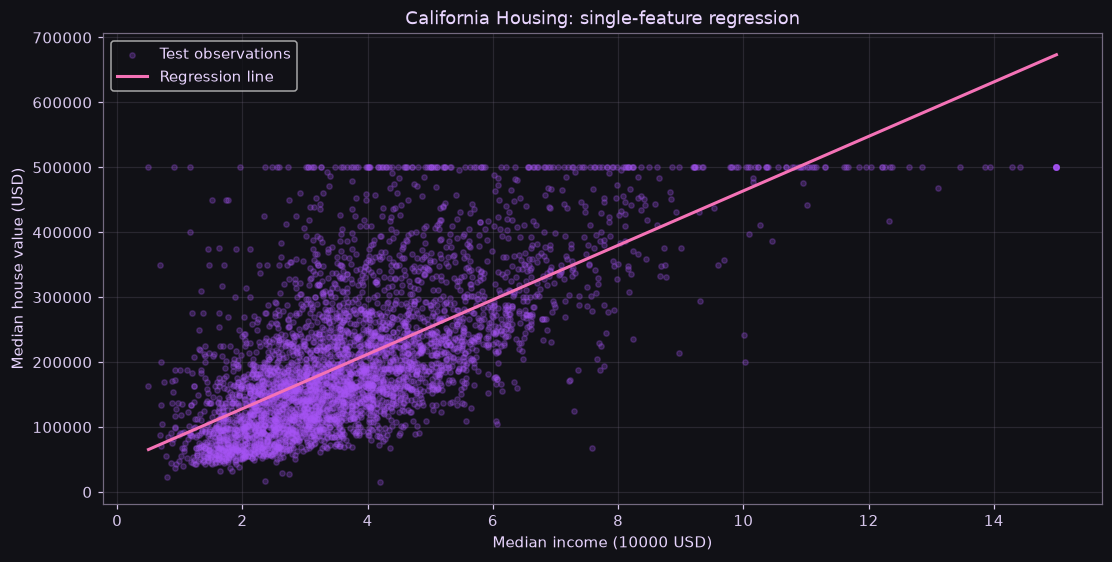

In [9]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)
train_correlations = train_df.corr()["MedHouseVal"].drop("MedHouseVal")
best_feature = str(train_correlations.abs().idxmax())
colorize(train_correlations.sort_values(key=abs, ascending=False).round(4))
colorize(f"selected feature: {best_feature}")

housing_model = LinearRegression()
housing_model.fit(train_df[[best_feature]], train_df["MedHouseVal"])
test_predictions = housing_model.predict(test_df[[best_feature]])
actual_usd = test_df["MedHouseVal"] * 100000
predicted_usd = test_predictions * 100000
housing_mae = mean_absolute_error(actual_usd, predicted_usd)
housing_rmse = root_mean_squared_error(actual_usd, predicted_usd)
housing_r2 = r2_score(actual_usd, predicted_usd)
colorize(f"test MAE: {housing_mae:.2f} USD\ntest RMSE: {housing_rmse:.2f} USD\ntest R²: {housing_r2:.4f}")

feature_grid = pd.DataFrame({
    best_feature: np.linspace(test_df[best_feature].min(), test_df[best_feature].max(), 200)
})
fig, ax = plt.subplots(layout="constrained")
ax.scatter(test_df[best_feature], actual_usd, color=PURPLE, alpha=0.25, s=12, label="Test observations")
ax.plot(feature_grid[best_feature], housing_model.predict(feature_grid) * 100000, color=PINK, label="Regression line")
ax.set(title="California Housing: single-feature regression", xlabel="Median income (10000 USD)", ylabel="Median house value (USD)")
ax.legend()
ax.grid()
ax.set_axisbelow(True)
plt.show()

<span style="color: #a855f7">MedInc має найсильнішу абсолютну кореляцію з ціною на train, одна ознака пояснює лише частину варіації цін, значний розкид навколо прямої показує обмеження простої моделі, кореляція не доводить причинність</span>